# Reward change-point design: ideal-observer optimal bounds

Design notebook for the RC (reward change) task in `task/RC/`. Solver: `pigeon.ideal_observer`.

## The task

Four 1000-step blocks, all at one difficulty: each of Petey's steps moves 0.01 toward the correct pile on
average, with SD 0.05 (MXSC's low SNR, 0.2). Each trial costs 5 steps to start, each error 10 extra steps,
and a trial with no response by step 50 times out with no coins.

| Block | Coins (correct / error) |
|---|---|
| Block 1: low reward (fixed) | +1 / −1 |
| Block 2: high reward (fixed) | +3 / −3 |
| Rising reward | +1 / −1, then +3 / −3 from the switch step on |
| Falling reward | +3 / −3, then +1 / −1 from the switch step on |

The switch step is the participant's median response time (in steps) in the two fixed blocks, pooled.
Each reward-change block is compared with the fixed block that has the same starting reward
(rising with Block 1, falling with Block 2).

## The ideal observer

Sees Petey's exact position, knows the difficulty but not the direction, and at each step either responds
(choosing the likelier pile) or waits. It maximizes coins per step, the right objective for a
step-budgeted block, by dynamic programming (`get_optimal_bounds`; see the module docstring). The optimal
bound at a step is the distance from the start beyond which responding beats waiting. It has no
non-decision time and no perceptual noise.

## Questions

1. What are the optimal bounds in each of the four blocks?
2. How much do they depend on the switch step, which differs across participants?

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pigeon.ideal_observer import MAX_STEPS, get_optimal_bounds
from pigeon.plotting import FONT_RC, OPTIMAL_COLOR

LOW, HIGH = (1, 1), (3, 3)
BLOCKS = {  # name: (reward before the switch, reward after)
    'Block 1: low reward': (LOW, LOW),
    'Block 2: high reward': (HIGH, HIGH),
    'Rising reward': (LOW, HIGH),
    'Falling reward': (HIGH, LOW),
}
MATCHED = {'Rising reward': 'Block 1: low reward', 'Falling reward': 'Block 2: high reward'}
SWITCH = 9                          # the typical MXSC participant's switch step (median of B3 change points)
SWITCHES = (3, 6, 9, 13, 20, 25)    # MXSC range: quartiles 6 / 9 / 13, min 3, max 25
REFERENCE_GRAY = (0.55, 0.55, 0.55)

plt.rcParams.update({'font.size': 12, 'axes.labelsize': 12, 'axes.titlesize': 12, 'xtick.labelsize': 12,
                     'ytick.labelsize': 12, 'axes.spines.top': False, 'axes.spines.right': False, **FONT_RC})

def plot_block_pair(ax, steps, matched_bound, change_bound, switch, matched_name, change_name, ymax=0.3,
                    label_never=True, legend=True):
    """Optimal bound of a reward-change block (red) over its matched fixed block's (gray dashed)."""
    ax.axvline(switch, color=(0.8, 0.8, 0.8), lw=1, zorder=0)
    ax.plot(steps, matched_bound, color=REFERENCE_GRAY, lw=2, ls='--', label=matched_name.split(':')[0] + ' (fixed)')
    ax.plot(steps, change_bound, color=OPTIMAL_COLOR, lw=2, label=change_name)
    never = np.isnan(change_bound)
    if never.any():   # waiting is optimal at every position: a bar along the top edge
        ax.plot(steps[never], np.full(never.sum(), ymax), color=OPTIMAL_COLOR, lw=5, solid_capstyle='butt',
                clip_on=False)
        if label_never:
            ax.text(switch + 1, ymax - 0.01, 'never respond', fontsize=8, color=OPTIMAL_COLOR, va='top')
    ax.set_xlim(0, MAX_STEPS)
    ax.set_ylim(0, ymax)
    if legend:
        ax.legend(loc='center right', fontsize=8, frameon=False)

## 1. Optimal bounds in the four blocks (switch at step 9)

Reward rate and the optimal bound at selected steps. "never" = waiting is optimal whatever Petey's
position.

In [2]:
res = {name: get_optimal_bounds(pre, post, SWITCH) for name, (pre, post) in BLOCKS.items()}
show = [1, 5, SWITCH - 1, SWITCH, 15, 30, 45]
table = pd.DataFrame({name: [1000 * rho] + list(b[show]) for name, (rho, b) in res.items()},
                     index=['coins per 1000 steps'] + [f'bound at step {s}' for s in show]).T
print(table.round(3).fillna('never').to_string())

                      coins per 1000 steps bound at step 1 bound at step 5 bound at step 8  bound at step 9  bound at step 15  bound at step 30  bound at step 45
Block 1: low reward                 34.364           0.122           0.122           0.122            0.122             0.122             0.120             0.094
Block 2: high reward               103.093           0.122           0.122           0.122            0.122             0.122             0.120             0.094
Rising reward                       94.848           never           never           never            0.132             0.132             0.128             0.098
Falling reward                      93.027           0.112           0.088           0.016            0.048             0.048             0.048             0.056


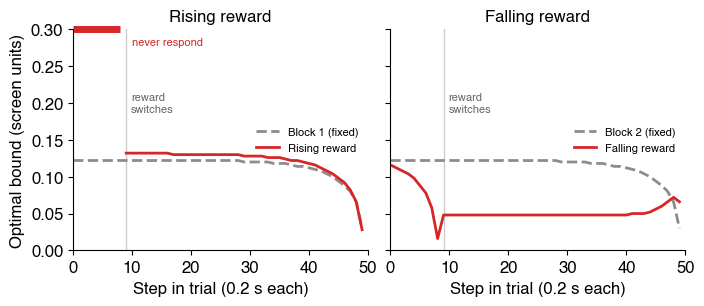

In [3]:
steps = np.arange(MAX_STEPS)
fig, axs = plt.subplots(1, 2, figsize=(17.6 / 2.54, 7.5 / 2.54), sharey=True, layout='constrained')
for ax, (change_name, matched_name) in zip(axs, MATCHED.items()):
    plot_block_pair(ax, steps, res[matched_name][1], res[change_name][1], SWITCH, matched_name, change_name)
    ax.text(SWITCH + 0.8, 0.2, 'reward\nswitches', fontsize=8, va='center', color=(0.4, 0.4, 0.4))
    ax.set_title(change_name)
    ax.set_xlabel('Step in trial (0.2 s each)')
axs[0].set_ylabel('Optimal bound (screen units)')
plt.show()

**What it shows**

- **Blocks 1 and 2 have identical optimal bounds**: flat at about 0.12, dropping near the 50-step timeout.
  Tripling both gain and loss triples the coins (34 vs 103 per 1000 steps) but cannot change which policy is
  best, so the two fixed blocks are normatively equivalent baselines.
- **Rising reward: never respond before the switch.** Waiting a few steps triples the payoff whatever Petey
  is doing. After the switch the bound is about 0.13, slightly above Block 1's.
- **Falling reward: respond sooner as the switch approaches.** The bound falls from about 0.11 to almost 0
  at the step before the switch (the last chance at 3 coins), then stays at about 0.05, well below Block 2's
  0.12: time is still valued at the high-reward rate (93 coins per 1000 steps) while each answer now pays
  1 coin. Near the timeout it rises, because with the error charge a weak guess loses coins on average.
- For scale: the ideal bound (0.12) is about half the fitted bound plateau of the MXSC participants at this
  difficulty (about 0.23); real participants also have a non-decision time and perceptual noise.

## 2. Dependence on the switch step

The switch step is each participant's own median response time, which varied from 3 to 25 steps in MXSC
(quartiles 6 / 9 / 13). Same layout as above, one row per switch step.

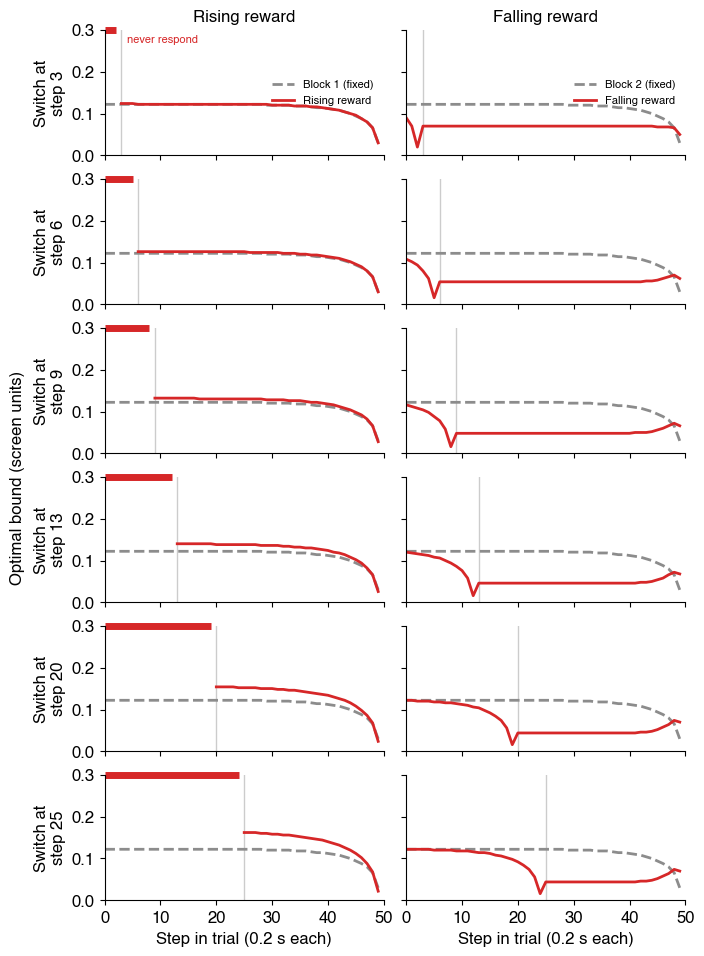

fixed blocks: bound 0.122
         block  switch step  coins per 1000 steps  steps of never-respond before the switch  bound at step before switch  median bound, 10 steps after switch
 Rising reward            3               102.722                                         3                          NaN                                0.122
Falling reward            3                64.183                                         0                        0.020                                0.070
 Rising reward            6                99.667                                         6                          NaN                                0.126
Falling reward            6                84.350                                         0                        0.016                                0.054
 Rising reward            9                94.848                                         9                          NaN                                0.132
Falling reward            

In [4]:
rows = []
fig, axs = plt.subplots(len(SWITCHES), 2, figsize=(17.6 / 2.54, 24 / 2.54), sharex=True, sharey=True,
                        layout='constrained')
for ri, sw in enumerate(SWITCHES):
    for ci, (change_name, matched_name) in enumerate(MATCHED.items()):
        rho, b = get_optimal_bounds(*BLOCKS[change_name], sw)
        plot_block_pair(axs[ri, ci], steps, res[matched_name][1], b, sw, matched_name, change_name,
                        label_never=(ri == 0), legend=(ri == 0))
        pre = b[1:sw]
        rows.append({'block': change_name, 'switch step': sw, 'coins per 1000 steps': 1000 * rho,
                     'steps of never-respond before the switch': int(np.isnan(b[:sw]).sum()),
                     'bound at step before switch': b[sw - 1],
                     'median bound, 10 steps after switch': np.nanmedian(b[sw:sw + 10])})
        if ri == 0:
            axs[ri, ci].set_title(change_name)
        if ci == 0:
            axs[ri, ci].set_ylabel(f'Switch at\nstep {sw}')
for ax in axs[-1]:
    ax.set_xlabel('Step in trial (0.2 s each)')
fig.supylabel('Optimal bound (screen units)', fontsize=12)
plt.show()
print(f"fixed blocks: bound {res['Block 1: low reward'][1][5]:.3f}")
print(pd.DataFrame(rows).round(3).to_string(index=False))

**What it shows**

- **The dynamics relative to the switch are the same at every switch step.** Rising reward: never respond
  before the switch, for switches as late as step 25; after it the bound is 0.12 (switch 3) to 0.16
  (switch 25). Falling reward: the bound stays at Block 2's level until about 10 steps before the switch,
  ramps to nearly 0 at the step before it, then settles at 0.045–0.07.
- So per-participant switch steps (the MXSC design) are fine, and keep about half of each participant's
  trials ending on each side of the switch.

**Implications for the analysis**

1. Align measures to the switch, not to the start of the trial: the falling-reward ramp covers about the last
   10 steps before the switch whatever the switch step, so a single tilt fit from step 1 dilutes it for
   participants with late switches. Participants with early switches (3–6 steps; about a quarter in MXSC)
   have a pre-switch window shorter than the ramp.
2. The rising-reward prediction needs no model: the fraction of responses before the switch, compared with
   the same steps in Block 1.
3. The falling-reward post-switch drop is a strong prediction, but few trials last past the switch once the
   pre-switch bound falls, so it will be hard to measure.